# ContinuityGuard · RASCALS
## 01 — Native LinuxONE training and evaluation

All telemetry below is generated by our controlled service simulator. No hospital or patient data is used. Models learn only observable current/past features. Train, calibration, validation and test contain independent runs and distinct seeds.

Run all cells on the supplied LinuxONE Jupyter environment. This notebook calls the repository's original, inspectable implementation.

In [1]:
from pathlib import Path
import os, sys, platform, json
ROOT = Path.cwd()
if not (ROOT / 'continuityguard').is_dir():
    ROOT = ROOT.parent
assert (ROOT / 'continuityguard').is_dir(), 'Open this notebook from the project notebooks folder'
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))
print('Team: RASCALS')
print('Architecture:', platform.machine())
print('Python:', platform.python_version())
print('Project:', ROOT)
assert platform.machine() == 's390x', 'This submission notebook is intended to run on LinuxONE'


Team: RASCALS
Architecture: s390x
Python: 3.12.15
Project: /home/ibm-user/shared/continuityguard


### Train, calibrate, select, then evaluate
Three forecast candidates and their alert policies compete jointly on validation incident precision/early recall under a false-alarm budget. A separate calibration split fits sigmoid calibration; PR-AUC is also reported. Final testing uses fresh 50000-series seeds after the v1 development report was inspected. Isolation Forest learns normal behavior including healthy demand changes.

In [2]:
from continuityguard.train import main
main(ROOT / 'artifacts')

Generating independent runs


Fitting logistic_regression


Fitting boosted_trees_7_leaves


Fitting boosted_trees_15_leaves


{
  "selected": "boosted_trees_7_leaves",
  "policy": {
    "mode": "forecast",
    "forecast_threshold": 0.8,
    "novelty_threshold": 0.6049514944657695,
    "novelty_quantile": 0.995
  },
  "final_test": {
    "incidents": 47,
    "alerts": 70,
    "detected": 43,
    "early_detections": 43,
    "late_detections": 0,
    "missed": 4,
    "incident_precision": 0.6142857142857143,
    "incident_recall": 0.9148936170212766,
    "early_warning_recall": 0.9148936170212766,
    "median_early_lead_seconds": 37.0,
    "healthy_service_hours": 10.0,
    "healthy_false_alerts": 0,
    "false_alarms_per_healthy_service_hour": 0.0,
    "unmatched_alerts_all_runs": 27
  },
  "elapsed_seconds": 29.97
}


### Incident-level results
Misses and late detections are included. No point adjustment is used. Lead time is reported among early detections alongside the overall early-warning recall.

In [3]:
import pandas as pd
report = json.loads((ROOT / 'artifacts/report.json').read_text())
columns = ['incidents', 'incident_precision', 'incident_recall', 'early_warning_recall', 'median_early_lead_seconds', 'false_alarms_per_healthy_service_hour', 'missed']
display(pd.DataFrame(report['systems']).T[columns])
print('Chosen forecast:', report['selected_model'])
print('Alert policy:', report['policy'])
print('Forecast test:', {k: v for k,v in report['forecast_test'].items() if k != 'reliability_bins'})


,incidents,incident_precision,incident_recall,early_warning_recall,median_early_lead_seconds,false_alarms_per_healthy_service_hour,missed
Static thresholds,47,0.68254,0.914894,0.893617,9.0,0.0,4
Robust statistics,47,0.202703,0.638298,0.638298,36.5,1.5,17
Isolation Forest,47,0.266667,0.851064,0.851064,46.0,0.5,7
ContinuityGuard,47,0.614286,0.914894,0.914894,37.0,0.0,4


Chosen forecast: boosted_trees_7_leaves
Alert policy: {'mode': 'forecast', 'forecast_threshold': 0.8, 'novelty_threshold': 0.6049514944657695, 'novelty_quantile': 0.995}
Forecast test: {'pr_auc': 0.8498952414167404, 'brier_score': 0.016647466000935123, 'positive_prevalence': 0.05022176087571954}


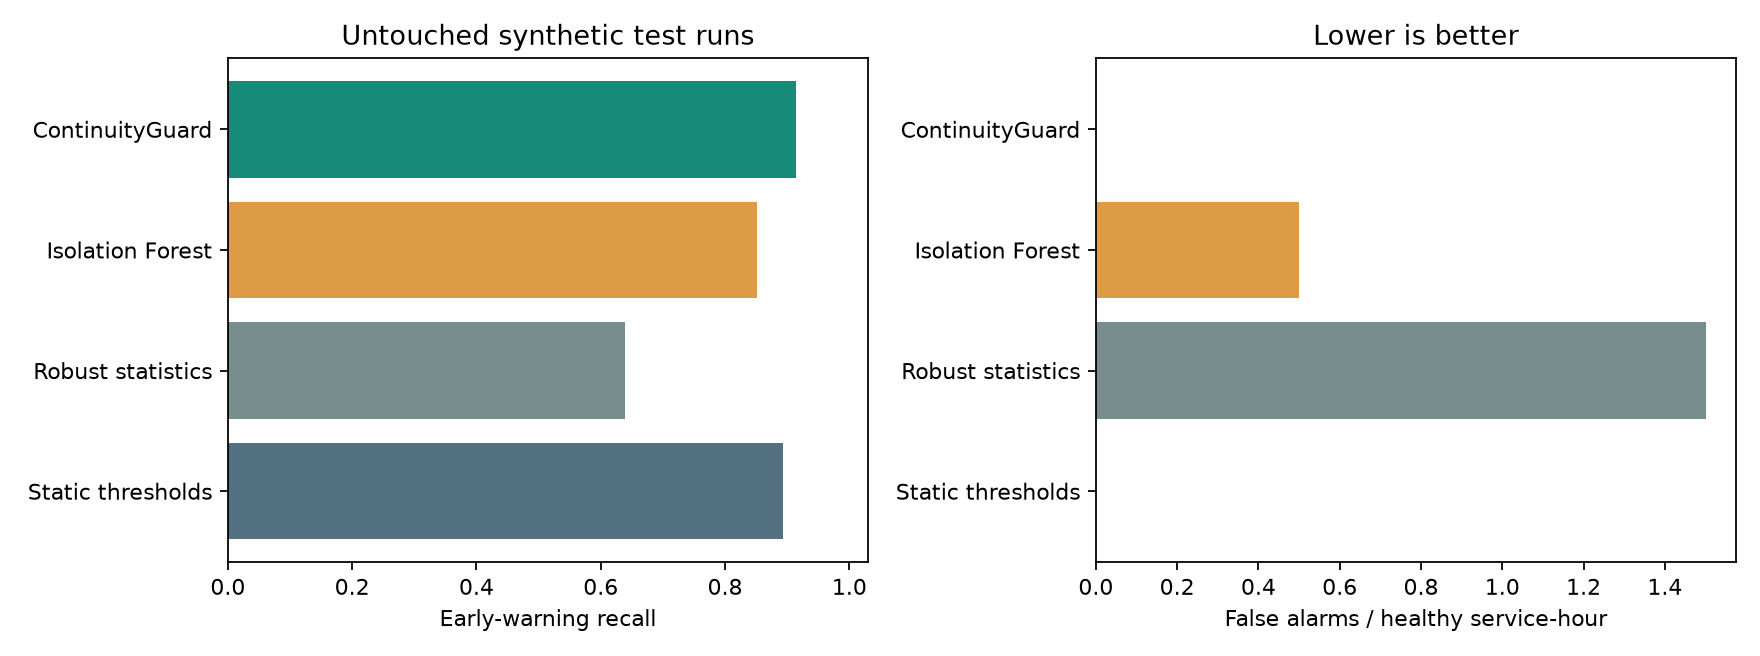

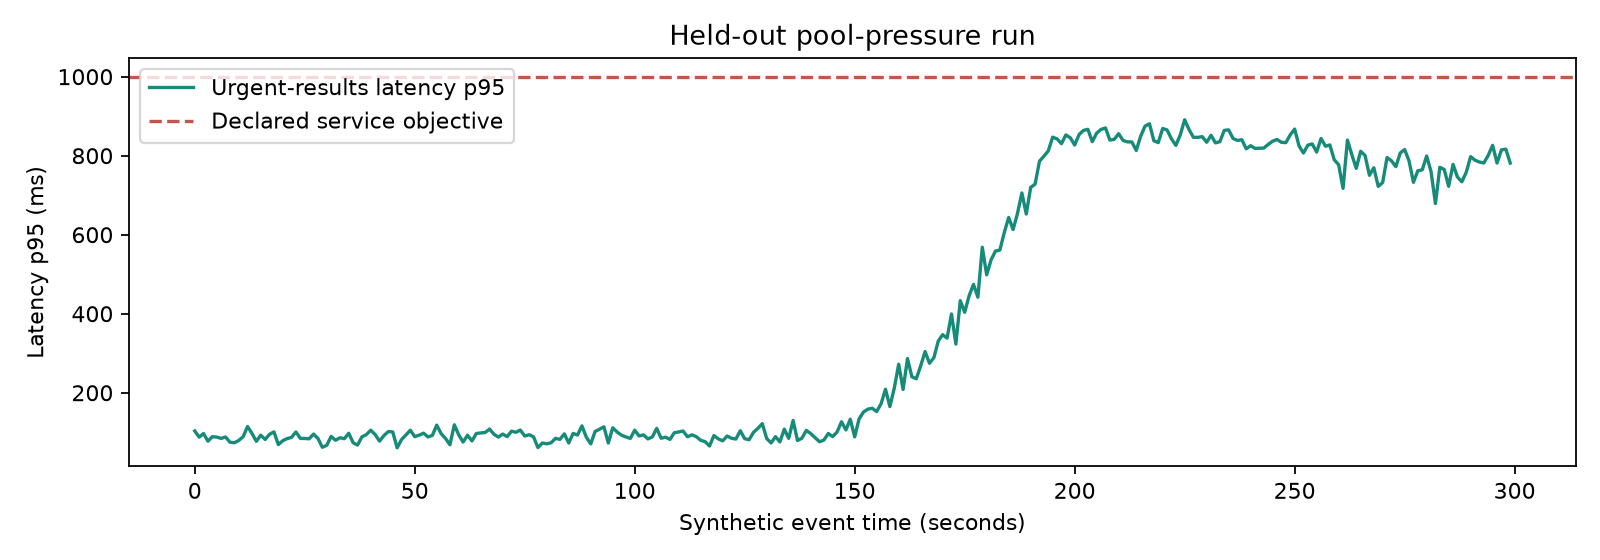

In [4]:
from IPython.display import display, Image
display(Image(filename=str(ROOT / 'artifacts/benchmark.png')))
display(Image(filename=str(ROOT / 'artifacts/example-timeline.png')))

### Stress test and paired response
Abrupt failures are unseen during fitting and may provide no warning precursor. Response comparisons share the same exogenous demand and random seed. Their effect sizes depend on the declared simulator assumptions.

In [5]:
print('Splits:', report['split'])
print('Unseen abrupt failures:', {k:v for k,v in report['unseen_abrupt_failures'].items() if k != 'incident_details'})
display(pd.DataFrame(report['paired_responses']))
print('Model integrity:', report['manifest']['sha256'])
print('Scope:', report['scope'])
print('Limitations:', *report['limitations'], sep='\n- ')


Splits: {'training_runs': 60, 'calibration_runs': 18, 'validation_runs': 24, 'test_runs': 60, 'unseen_abrupt_runs': 6, 'no_shared_seeds': True, 'seconds_per_run': 300, 'forecast_training_rows': 53106}
Unseen abrupt failures: {'incidents': 24, 'alerts': 24, 'detected': 24, 'early_detections': 0, 'late_detections': 24, 'missed': 0, 'incident_precision': 1.0, 'incident_recall': 1.0, 'early_warning_recall': 0.0, 'median_early_lead_seconds': None, 'healthy_service_hours': 0.0, 'healthy_false_alerts': 0, 'false_alarms_per_healthy_service_hour': None, 'unmatched_alerts_all_runs': 0}


,scope,action,action_at_second,urgent_success_without,urgent_success_with,urgent_success_difference,urgent_breach_seconds_without,urgent_breach_seconds_with,deferred_batch_requests,same_exogenous_seed
0,paired synthetic experiment; effects are simul...,defer_batch,141,2280,2574,294,100,0,1418,50300
1,paired synthetic experiment; effects are simul...,defer_batch,150,2363,2525,162,9,0,1381,50301
2,paired synthetic experiment; effects are simul...,defer_batch,135,2468,2807,339,100,0,1529,50302
3,paired synthetic experiment; effects are simul...,defer_batch,162,2204,2277,73,0,0,1252,50303
4,paired synthetic experiment; effects are simul...,defer_batch,139,2411,2611,200,17,0,1467,50305
5,paired synthetic experiment; effects are simul...,defer_batch,206,1432,1514,82,0,0,835,50306
6,paired synthetic experiment; effects are simul...,defer_batch,146,2216,2543,327,111,0,1394,50307
7,paired synthetic experiment; effects are simul...,defer_batch,182,1918,1987,69,0,0,1092,50308
8,paired synthetic experiment; effects are simul...,defer_batch,144,2337,2650,313,106,0,1436,50309
9,paired synthetic experiment; effects are simul...,cap_retries,184,1867,2002,135,2,0,0,50400


Model integrity: 98d7f1a718dd5529f4e838de13a7db2293f819791d50d1904910c5b94a2e8d7a
Scope: Synthetic service-simulator evaluation on LinuxONE; not real hospital validation
Limitations:
- Synthetic data and simulator intervention assumptions
- Declared topology and heuristic suspected cause, not causal proof
- Calibrated model output is conditional on the synthetic distribution
- Abrupt incidents can have no observable warning precursor
- No production hospital, z/OS or accelerator validation
